# Analizando los datos de las matrices de confusión de los modelos para elegir el más adecuado para nuestro negocio

Tras comparar los resultados obtenidos en las matrices de confusión de test, la red neuronal presenta el mejor rendimiento global, aunque las diferencias respecto a la regresión logística son reducidas.

La red neuronal obtiene una accuracy de 0,6683, una precision de 0,7379, un recall de 0,3002, un F1-score de 0,4267 y un ROC-AUC de 0,6826. Por su parte, la regresión logística alcanza una accuracy de 0,6641, una precision de 0,7266, un recall de 0,2938, un F1-score de 0,4184 y un ROC-AUC de 0,6802.

Aunque la red neuronal supera ligeramente a la regresión logística en todas las métricas, la diferencia no es suficientemente amplia como para afirmar que existe una superioridad significativa. Por ello, se considera la candidata principal, teniendo en cuenta también su complejidad y las necesidades de interpretación del proyecto.

In [20]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split

## Carga del modelo y preprocesamiento

In [21]:
paquete = joblib.load(
    "../model/RedNeuronal_completo.joblib"
)

modelo = paquete["modelo"]
encoder = paquete["encoder"]

stats_cluster = paquete["stats_cluster"]
stats_global = paquete["stats_global"]

columnas_cluster = paquete["columnas_cluster"]
columnas_globales = paquete["columnas_globales"]

texto = paquete["columnas_categoricas"]
cluster_col = paquete["cluster_col"]

columnas_modelo = paquete["columnas_modelo"]

print("Modelo y preprocesamiento cargados correctamente")
print("Número de columnas:", len(columnas_modelo))

Modelo y preprocesamiento cargados correctamente
Número de columnas: 11001


In [22]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

## Separamos train y test

In [23]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.10, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(24923, 13) (2770, 13) (3078, 13)
En train: 41.14 % En validación:  41.16 %   en test: 41.13 %


## Imputación de datos en train, val y test

In [24]:
for col in columnas_cluster:
    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in columnas_globales:
    X_train[col] = X_train[col].fillna(stats_global[col])

In [25]:
for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

In [26]:
for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

In [27]:
print("Nulos en TRAIN:", X_train.isna().sum().sum())
print("Nulos en VALIDACIÓN:", X_val.isna().sum().sum())
print("Nulos en TEST:", X_test.isna().sum().sum())

Nulos en TRAIN: 0
Nulos en VALIDACIÓN: 0
Nulos en TEST: 0


## Aplicar el OneHotEncoder guardado

### Transformamos las variables categóricas con el encoder original

In [28]:
nombres = encoder.get_feature_names_out(texto)

cat_train = pd.DataFrame(
    encoder.transform(X_train[texto]),
    columns=nombres,
    index=X_train.index
)

cat_val = pd.DataFrame(
    encoder.transform(X_val[texto]),
    columns=nombres,
    index=X_val.index
)

cat_test = pd.DataFrame(
    encoder.transform(X_test[texto]),
    columns=nombres,
    index=X_test.index
)

c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


### Sustituimos las variables categóricas originales

In [29]:
X_train = pd.concat(
    [X_train.drop(columns=texto), cat_train],
    axis=1
)

X_val = pd.concat(
    [X_val.drop(columns=texto), cat_val],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=texto), cat_test],
    axis=1
)

### Recuperamos exactamente el orden de columnas del entrenamiento

In [30]:
X_train = X_train[columnas_modelo]
X_val = X_val[columnas_modelo]
X_test = X_test[columnas_modelo]

### Convertimos a formato numérico compatible con Keras

In [31]:
X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)
X_test = X_test.astype(np.float32)

print("Train:", X_train.shape)
print("Validación:", X_val.shape)
print("Test:", X_test.shape)

assert X_train.shape[1] == len(columnas_modelo)
assert X_val.columns.equals(X_train.columns)
assert X_test.columns.equals(X_train.columns)

print("Preprocesamiento reproducido correctamente")

Train: (24923, 11001)
Validación: (2770, 11001)
Test: (3078, 11001)
Preprocesamiento reproducido correctamente


## Preparamos las muestras para Shap 

In [32]:
background = X_train.sample(n=min(50, len(X_train)), random_state=42)
X_explicar = X_val.sample(n=min(100, len(X_val)), random_state=42)

nombres_columnas = X_explicar.columns

background = background.to_numpy(dtype=np.float32)
X_explicar_np = X_explicar.to_numpy(dtype=np.float32)

print("Background:", background.shape)
print("Canciones explicadas:", X_explicar_np.shape)

Background: (50, 11001)
Canciones explicadas: (100, 11001)


## Calculamos los valores Shap

In [33]:
explainer = shap.GradientExplainer(modelo, background)

shap_values = explainer.shap_values(X_explicar_np)

if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3 and shap_values.shape[-1] == 1:
    shap_values = shap_values[:, :, 0]

print("Dimensiones de los valores SHAP:", shap_values.shape)
print("Dimensiones esperadas:", X_explicar_np.shape)

c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_2
Received: inputs=['Tensor(shape=(100, 11001))']
  warnings.warn(msg)
c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_2
Received: inputs=['Tensor(shape=(50, 11001))']
  warnings.warn(msg)


Dimensiones de los valores SHAP: (100, 11001)
Dimensiones esperadas: (100, 11001)


## Primer gráfico: Importancia global

- Nos permite saber: 
    - Qué variables tienen mayor influencia en las predicciones.
    - Si los valores altos o bajos de una variable empujan la predicción hacia Top 30.
    - Qué variables tienen efectos diferentes según la canción.

C:\Users\Xabier.garcia\AppData\Local\Temp\ipykernel_9208\3257097834.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


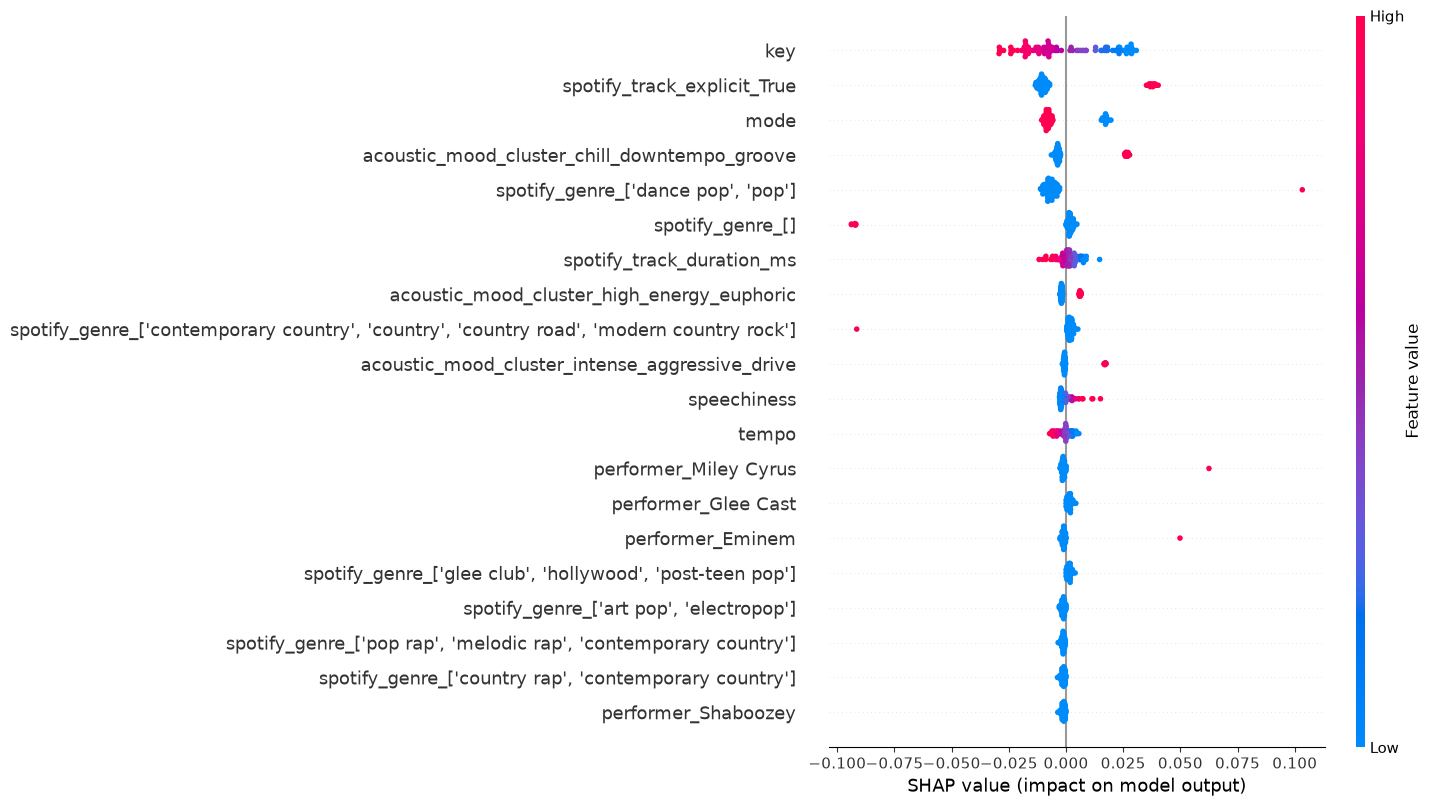

In [34]:
shap.summary_plot(
    shap_values,
    X_explicar_np,
    feature_names=nombres_columnas,
    max_display=20
)

## Segundo gráfico: Ranking de importancia

- Este gráfico ordena las variables según la media de sus valores SHAP absolutos.

C:\Users\Xabier.garcia\AppData\Local\Temp\ipykernel_9208\3502701846.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


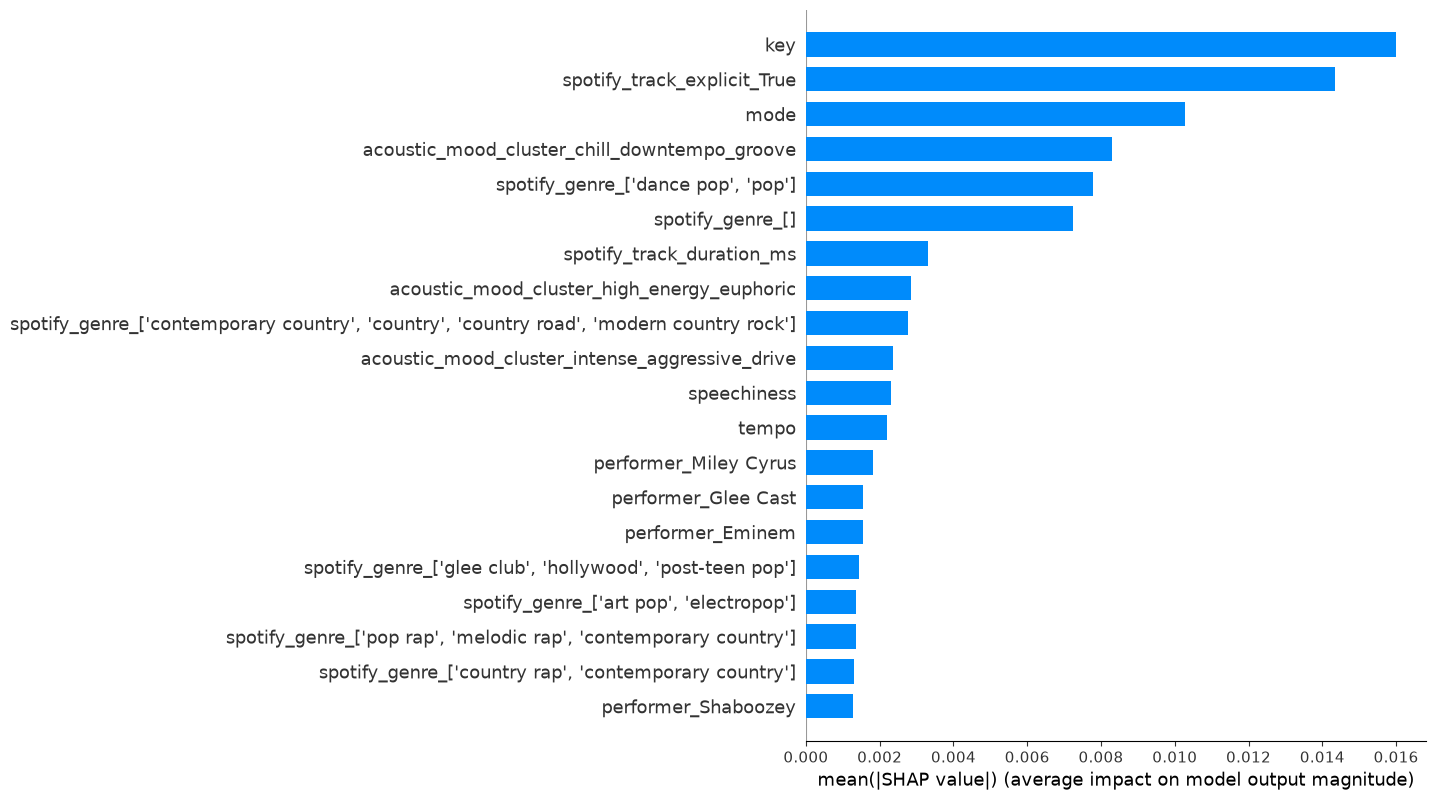

In [35]:
shap.summary_plot(
    shap_values,
    X_explicar_np,
    feature_names=nombres_columnas,
    plot_type="bar",
    max_display=20
)

## Agrupamos las variables categóricas

Al utilizar OneHotEncoder, tenemos miles de columnas y muchas de ellas correspondientes a artistas. Si no agrupamos las categorías, el ranking podría mostrar muchos artistas individuales y ocultar la importancia global de "performer".

Por ello vamos a calcular el peso conjunto de cada variable.

variable_original
spotify_genre                0.055018
performer                    0.035719
key                          0.016007
spotify_track_explicit       0.014354
acoustic_mood_cluster        0.013968
mode                         0.010282
spotify_track_duration_ms    0.003300
speechiness                  0.002302
tempo                        0.002206
instrumentalness             0.000839
time_signature               0.000259
danceability                 0.000056
loudness                     0.000012
Name: importancia, dtype: float64

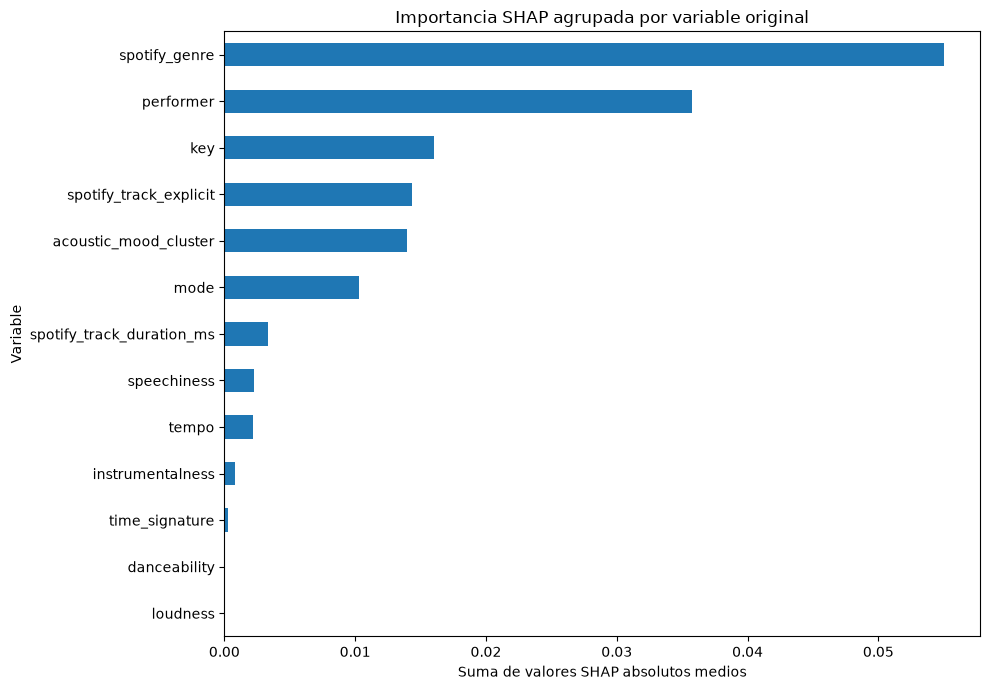

In [36]:
importancias = np.abs(shap_values).mean(axis=0)

df_shap = pd.DataFrame({
    "variable_codificada": nombres_columnas,
    "importancia": importancias
})

variables_originales = [
    "performer",
    "spotify_genre",
    "acoustic_mood_cluster",
    "spotify_track_explicit"
]

def obtener_variable_original(nombre):
    for variable in variables_originales:
        if nombre.startswith(variable + "_"):
            return variable
    return nombre

df_shap["variable_original"] = (
    df_shap["variable_codificada"]
    .map(obtener_variable_original)
)

importancia_agrupada = (
    df_shap.groupby("variable_original")["importancia"]
    .sum()
    .sort_values(ascending=False)
)

display(importancia_agrupada)

importancia_agrupada.sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Importancia SHAP agrupada por variable original"
)

plt.xlabel("Suma de valores SHAP absolutos medios")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()